# Практическая работа №2. Базовые нейронные сети

Были рассмотрены полносвязная, свёрточная и рекуррентная архитектуры на больших наборах данных. Каждый раздел содержит подготовку данных, анализ, обучение и оценку на Test.

In [ ]:
%pip install -q numpy pandas matplotlib scipy scikit-learn torch certifi

В первой кодовой ячейке устанавливаются зависимости. Ключ `-q` сокращает служебный вывод pip. При успешной установке ошибок не появляется. PyTorch используется для вычисления градиентов и пакетного обучения.

In [1]:
import os, io, zipfile, gzip, struct, hashlib, math, json
from pathlib import Path
from urllib.request import urlopen, Request
import ssl
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score, mean_absolute_error,
    mean_squared_error, r2_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

Были подключены библиотеки для таблиц, графиков, разделения выборок и расчёта метрик. `torch.nn` содержит слои нейронных сетей, а `DataLoader` выдаёт пакеты примеров. Импорты сами по себе ничего не выводят.

In [2]:
get_ipython().run_line_magic("matplotlib", "inline")
DATA = Path(os.environ.get("ML_DATA_DIR", "data"))
DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all():
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
seed_all()

def fetch(url, name, md5=None):
    path = DATA / name
    def check(file, sha256=None):
        if file.suffix == ".part" and file.stat().st_size == 0:
            raise ValueError("Пустой файл")
        if md5 and hashlib.md5(file.read_bytes()).hexdigest() != md5:
            raise ValueError("Неверная контрольная сумма MD5")
        if sha256 and hashlib.sha256(file.read_bytes()).hexdigest() != sha256:
            raise ValueError("Неверная контрольная сумма SHA-256 резервного архива")
        if name.endswith(".zip"):
            with zipfile.ZipFile(file) as archive:
                if archive.testzip() is not None:
                    raise ValueError("Повреждённый ZIP")
    if path.exists():
        try:
            check(path)
            return path
        except (OSError, ValueError, zipfile.BadZipFile) as exc:
            print(f"Кэш {name} повреждён: {exc}. Повторная загрузка.")
    sources = [(url, None)]
    if name == "bank_marketing.zip":
        # Резервная копия оригинального UCI bank.zip, содержащего bank-full.csv.
        sources.append(("https://raw.githubusercontent.com/raederhans/ca6003-bank-marketing/main/data/source/bank.zip",
                        "99d7e8eb12401ed278b793984423915411ea8df099e1795f9fefe254f513fe5e"))
    tmp = path.with_suffix(path.suffix + ".part")
    errors = []
    for address, sha256 in sources:
        for label, context in [("системные CA", ssl.create_default_context()),
                               ("certifi", ssl.create_default_context(cafile=certifi.where()))]:
            try:
                with urlopen(Request(address, headers={"User-Agent": "Python ML coursework"}),
                             timeout=120, context=context) as response, tmp.open("wb") as out:
                    while chunk := response.read(1024*1024):
                        out.write(chunk)
                check(tmp, sha256)
                tmp.replace(path)
                print(f"Загружен {name}: {address} ({label})")
                return path
            except (OSError, ValueError, zipfile.BadZipFile) as exc:
                tmp.unlink(missing_ok=True)
                errors.append(f"{address} ({label}): {exc}")
                print(errors[-1])
    raise RuntimeError(f"Не удалось безопасно скачать {name}. Проверьте дату Windows, сертификаты и соединение. "
                       f"Можно скачать оригинальный файл вручную и сохранить как {path}.\n" + "\n".join(errors))

def loader(x, y, batch=256, shuffle=False, regression=False):
    a = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32)
    b = torch.as_tensor(np.ascontiguousarray(y), dtype=torch.float32 if regression else torch.long)
    return DataLoader(TensorDataset(a,b), batch_size=batch, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(42), num_workers=0)

def evaluate(model, batches, loss_fn, regression=False):
    model.eval(); total=0.; count=0; outputs=[]; targets=[]
    with torch.no_grad():
        for x,y in batches:
            yhat=model(x.to(DEVICE)); y=y.to(DEVICE)
            total += loss_fn(yhat,y).item()*len(y); count += len(y)
            outputs.append(yhat.cpu().numpy()); targets.append(y.cpu().numpy())
    return total/count, np.concatenate(outputs), np.concatenate(targets)

def fit_net(model, train, val, loss_fn, epochs, lr, regression=False):
    model.to(DEVICE); optim=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]; best=float("inf"); best_state=None
    for epoch in range(1,epochs+1):
        model.train(); sum_loss=0.; count=0
        for x,y in train:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optim.zero_grad(); pred=model(x); loss=loss_fn(pred,y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.0); optim.step()
            sum_loss+=loss.item()*len(y); count+=len(y)
        vloss, vp, vy=evaluate(model,val,loss_fn,regression)
        score=float(np.sqrt(np.mean((vp-vy)**2))) if regression else float(np.mean(vp.argmax(1)==vy))
        history.append((epoch,sum_loss/count,vloss,score))
        if vloss<best:
            best=vloss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"Epoch {epoch:02d}: train loss={sum_loss/count:.4f}; val loss={vloss:.4f}; val score={score:.4f}")
    model.load_state_dict(best_state)
    return pd.DataFrame(history,columns=["epoch","train_loss","val_loss","val_score"])

def chart(title,xlabel,ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.tight_layout(); plt.show(); plt.close()

def heat(a,labels,title,xlabel,ylabel,fmt):
    a=np.asarray(a); plt.figure(figsize=(9,7)); plt.imshow(a,cmap="Blues",aspect="auto"); plt.colorbar()
    plt.xticks(range(len(labels)),labels,rotation=45,ha="right"); plt.yticks(range(len(labels)),labels)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            plt.text(j,i,format(a[i,j],fmt),ha="center",va="center",fontsize=7,
                     color="white" if a[i,j]>a.max()*0.55 else "black")
    chart(title,xlabel,ylabel)

def size_table(train,val,test):
    assert train>=20000, "Training set must contain at least 20,000 examples"
    return {"Train":int(train),"Validation":int(val),"Test":int(test)}

def class_metrics(y,p):
    return {"Accuracy":accuracy_score(y,p),"Macro Precision":precision_score(y,p,average="macro",zero_division=0),
            "Macro Recall":recall_score(y,p,average="macro",zero_division=0),"Macro F1":f1_score(y,p,average="macro",zero_division=0)}
print("Устройство:",DEVICE)

Устройство: cpu


`fetch` сохраняет исходный файл локально, при наличии контрольной суммы проверяет целостность. Для HTTPS используются системные сертификаты или набор `certifi`; проверка сертификатов остаётся включённой. Если основной источник Bank Marketing недоступен, используется копия исходного архива `bank.zip` с проверкой SHA-256. `loader` формирует батчи без копирования примеров между выборками. В `fit_net` последовательно выполняются прямой проход, вычисление функции потерь, `backward()` и обновление весов Adam. Валидация выполняется без градиентов; сохраняется состояние с минимальной ошибкой Validation. Test здесь не используется. `size_table` проверяет наличие не менее 20 000 обучающих примеров. В выводе ячейки указывается выбранное устройство CPU или CUDA.

# Полносвязная нейронная сеть (FCN)

Цель работы — классификация клиентов банка по вероятности оформления срочного вклада. Был использован полный набор `bank-full.csv`, содержащий 45 211 записей до очистки. Выполняются анализ табличных данных, кодирование категориальных признаков, обучение полносвязной сети и оценка на отдельной тестовой выборке.

Источник: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).

In [3]:
seed_all()
path=fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip","bank_marketing.zip")
with zipfile.ZipFile(path) as z:
    names=z.namelist()
    direct=next((x for x in names if x.endswith("bank-full.csv")),None)
    if direct: df=pd.read_csv(z.open(direct),sep=";")
    else:
        nested=next(x for x in names if x.split("/")[-1]=="bank.zip")
        with zipfile.ZipFile(io.BytesIO(z.read(nested))) as b:
            df=pd.read_csv(b.open(next(x for x in b.namelist() if x.endswith("bank-full.csv"))),sep=";")
assert df.shape == (45211, 17), f"Ожидалось 45211 строк и 17 столбцов: {df.shape}"
print("Исходный размер:",df.shape)
display(df.head()); df.info()

https://archive.ics.uci.edu/static/public/222/bank+marketing.zip (системные CA): <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: certificate has expired (_ssl.c:1032)>


Загружен bank_marketing.zip: https://archive.ics.uci.edu/static/public/222/bank+marketing.zip (certifi)
Исходный размер: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


Архив UCI содержит CSV с разделителем `;`, иногда во вложенном ZIP. `df.shape` показывает число записей и столбцов, `head()` — первые пять клиентов, а `info()` — типы и число непустых значений. Целевой столбец `y` содержит ответы yes/no. После чтения проверяется исходный размер: 45 211 строк и 17 столбцов.

In [4]:
display(df.isna().sum().to_frame("Пропуски")); print("Дубликаты:",df.duplicated().sum())
display(df.describe(include="all").T)
print("Неизвестные категории:"); display(df.eq("unknown").sum().sort_values(ascending=False))
num=df.select_dtypes(include="number").columns
q1,q3=df[num].quantile(.25),df[num].quantile(.75); iqr=q3-q1
display(((df[num]<q1-1.5*iqr)|(df[num]>q3+1.5*iqr)).sum().to_frame("IQR"))
# duration известен только после звонка
features=df.drop(columns=["duration","y"])
valid=df.y.isin(["yes","no"]) & df.age.between(18,120) & df.day.between(1,31) & (df.campaign>=1) & (df.previous>=0) & (df.pdays>=-1)
print("Некорректных строк:",int((~valid).sum()))
clean=df.loc[valid].drop(columns="duration").dropna().drop_duplicates()
# одинаковый набор признаков с разными метками исключается из обеих групп
keys=clean.drop(columns="y").columns.tolist()
conflicts=clean.duplicated(subset=keys,keep=False)
print("Неоднозначные повторяющиеся признаки:",int(conflicts.sum()))
clean=clean.loc[~conflicts].reset_index(drop=True)
print("После очистки:",clean.shape)

,Пропуски
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Дубликаты: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Неизвестные категории:


poutcome     36959
contact      13020
education     1857
job            288
age              0
default          0
balance          0
housing          0
marital          0
loan             0
day              0
duration         0
month            0
campaign         0
pdays            0
previous         0
y                0
dtype: int64

,IQR
age,487
balance,4729
day,0
duration,3235
campaign,3064
pdays,8257
previous,8257


Некорректных строк: 0


Неоднозначные повторяющиеся признаки: 0
После очистки: (45195, 16)


`isna()` считает настоящие пропуски, `unknown` — отдельная категория, которую было решено сохранить. `describe()` показывает count, mean, std, квартили и диапазоны; IQR отмечает необычные значения, не обязательно ошибки. Были удалены невозможные записи, пропуски и повторы после исключения `duration` (длительность разговора неизвестна до звонка). `pdays=-1` означает отсутствие предыдущего контакта, а не ошибку. Строки с одинаковыми входами и противоположными метками исключены, чтобы не переносить их между выборками.

In [5]:
X=clean.drop(columns="y"); y=clean.y.eq("yes").astype(int).to_numpy()
i_train,i_temp=train_test_split(np.arange(len(y)),test_size=.30,stratify=y,random_state=42)
i_val,i_test=train_test_split(i_temp,test_size=.50,stratify=y[i_temp],random_state=42)
nums=X.select_dtypes(include="number").columns.tolist(); cats=X.select_dtypes(exclude="number").columns.tolist()
prep=ColumnTransformer([("num",StandardScaler(),nums),("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),cats)])
a=prep.fit_transform(X.iloc[i_train]).astype(np.float32)
b=prep.transform(X.iloc[i_val]).astype(np.float32); c=prep.transform(X.iloc[i_test]).astype(np.float32)
sizes=size_table(len(a),len(b),len(c)); print(sizes); print("Признаков после кодирования:",a.shape[1])
eda=clean.iloc[i_train].copy()

{'Train': 31636, 'Validation': 6779, 'Test': 6780}
Признаков после кодирования: 50


Разбиение 70/15/15 сделано со стратификацией по меткам. `fit_transform` вычисляет параметры стандартизации и список категорий только на Train; `transform` использует их для других частей. `sizes` содержит число уникальных строк после очистки, а второй вывод — число входов после one-hot-кодирования. Все следующие графики исходных признаков построены на Train.

### Распределение классов

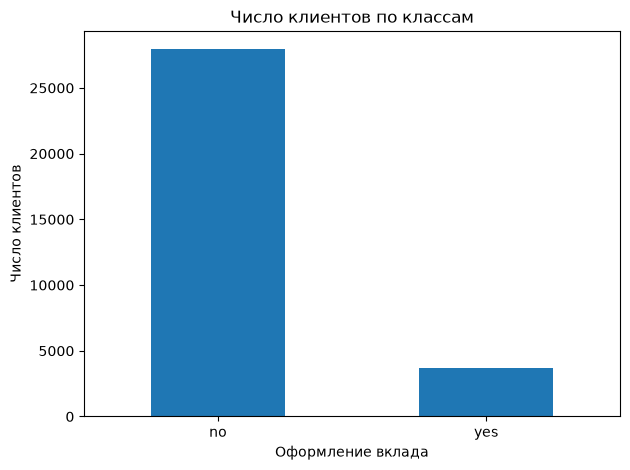

In [6]:
plt.figure(); eda.y.value_counts().reindex(["no","yes"]).plot.bar(rot=0); chart("Число клиентов по классам", "Оформление вклада", "Число клиентов")

Столбцы показывают количество клиентов с ответами no и yes. Различие высот отражает дисбаланс; поэтому одной Accuracy недостаточно, используется Macro F1 и полнота положительного класса.

### Гистограмма возраста

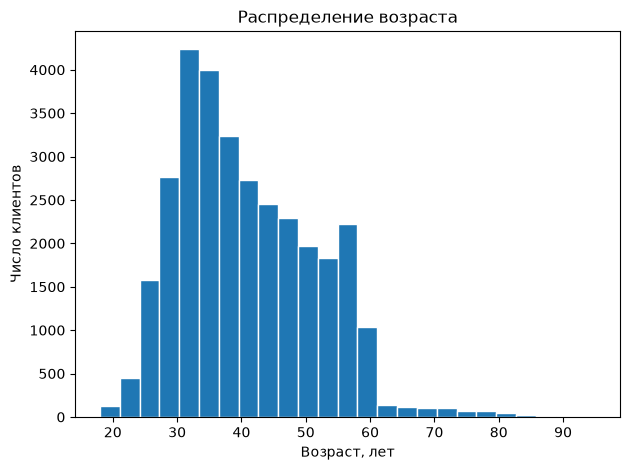

In [7]:
plt.figure(); plt.hist(eda.age,bins=25,edgecolor="white"); chart("Распределение возраста", "Возраст, лет", "Число клиентов")

Гистограмма делит возраст на 25 интервалов. Высота столбца соответствует числу клиентов; по форме можно определить наиболее распространённый возраст и крайние группы.

### Диаграмма размаха баланса

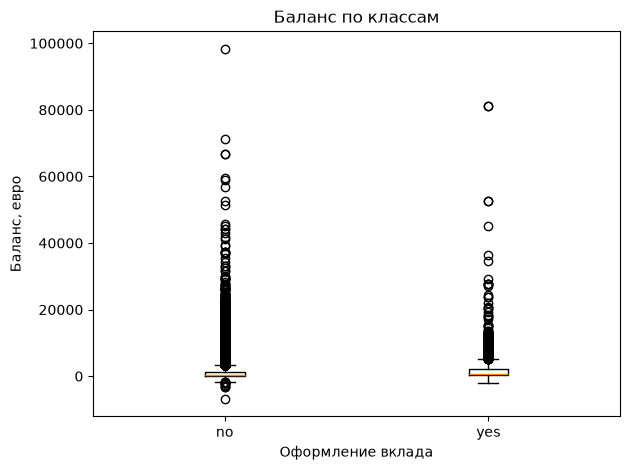

In [8]:
plt.figure(); plt.boxplot([eda.loc[eda.y==k,"balance"] for k in ["no","yes"]],tick_labels=["no","yes"],showfliers=True); chart("Баланс по классам", "Оформление вклада", "Баланс, евро")

Линия внутри коробки — медиана, границы — первый и третий квартили; усы ограничены правилом 1,5 IQR. Точки вне усов могут быть реальными крупными суммами. Сопоставляются различия распределений двух классов.

### Эмпирическая функция распределения

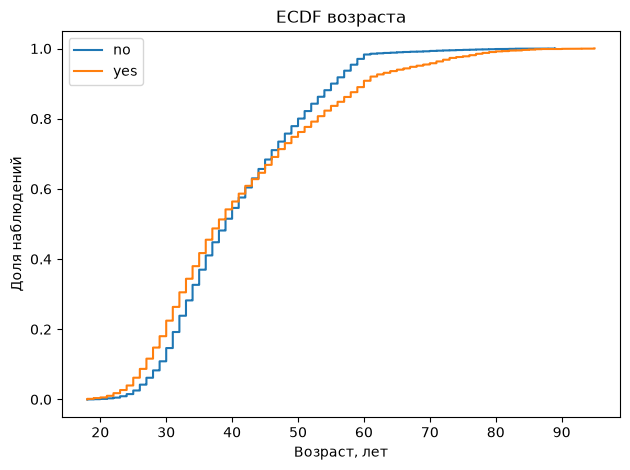

In [9]:
plt.figure();
for k in ["no","yes"]:
    v=np.sort(eda.loc[eda.y==k,"age"].to_numpy()); plt.step(v,np.arange(1,len(v)+1)/len(v),where="post",label=k)
plt.legend(); chart("ECDF возраста", "Возраст, лет", "Доля наблюдений")

ECDF показывает долю клиентов с возрастом не больше значения по X. Расхождение кривых отражает различие распределений, но не устанавливает причинную связь.

### Диаграмма рассеяния

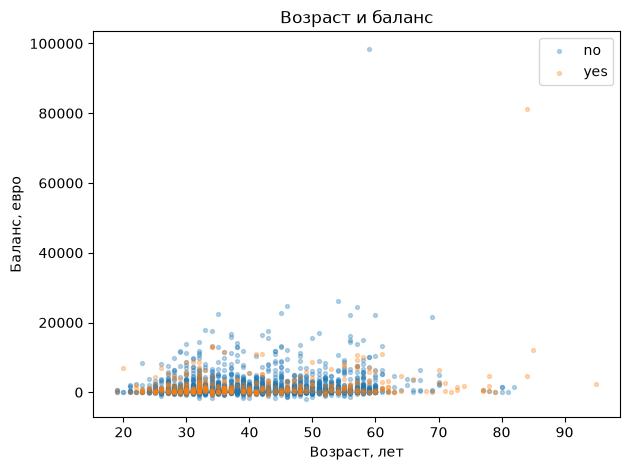

In [10]:
plt.figure(); sample=eda.sample(min(3000,len(eda)),random_state=42)
for k in ["no","yes"]:
    z=sample[sample.y==k]; plt.scatter(z.age,z.balance,s=8,alpha=.3,label=k)
plt.legend(); chart("Возраст и баланс", "Возраст, лет", "Баланс, евро")

Каждая точка — одна запись из случайной подвыборки Train для читаемости. Перекрытие цветов показывает, почему двух признаков может быть недостаточно для разделения классов. Обучение использует всю Train.

### Корреляционная матрица

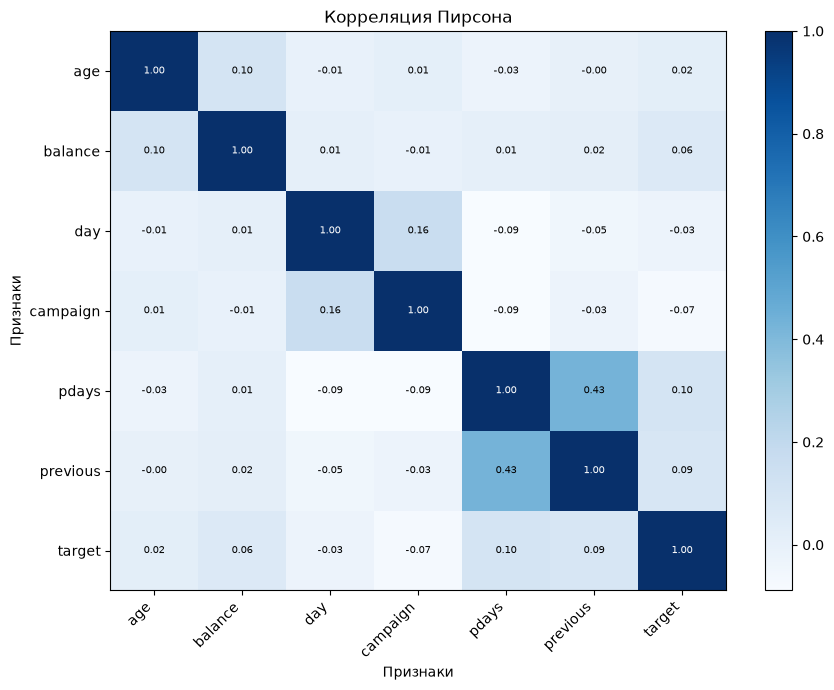

In [11]:
corr=eda[nums].assign(target=eda.y.eq("yes").astype(int)).corr(); heat(corr,corr.columns,"Корреляция Пирсона", "Признаки", "Признаки", ".2f")

Коэффициенты от −1 до 1 характеризуют линейную связь числовых признаков. Диагональ равна единице для непостоянных признаков; отрицательные значения не означают слабую связь. Корреляция не доказывает причинность.

In [12]:
train=loader(a,y[i_train],shuffle=True); val=loader(b,y[i_val]); test=loader(c,y[i_test])
model=nn.Sequential(nn.Linear(a.shape[1],64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,2))
weights=torch.tensor(len(i_train)/(2*np.bincount(y[i_train])),dtype=torch.float32,device=DEVICE)
loss_fn=nn.CrossEntropyLoss(weight=weights)
print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=20,lr=.001)
_, logits, true=evaluate(model,test,loss_fn)
prob=torch.softmax(torch.tensor(logits),dim=1).numpy()[:,1]; pred=logits.argmax(1)
m=class_metrics(true,pred); m.update({"Precision (yes)":precision_score(true,pred,zero_division=0),"Recall (yes)":recall_score(true,pred,zero_division=0),"ROC-AUC":roc_auc_score(true,prob),"PR-AUC (AP)":average_precision_score(true,prob)})
print(m); print(classification_report(true,pred,target_names=["no","yes"],zero_division=0))

Sequential(
  (0): Linear(in_features=50, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)
Параметров: 5410


Epoch 01: train loss=0.6143; val loss=0.5700; val score=0.7383


Epoch 02: train loss=0.5626; val loss=0.5571; val score=0.7656


Epoch 03: train loss=0.5532; val loss=0.5584; val score=0.7137


Epoch 04: train loss=0.5485; val loss=0.5574; val score=0.8124


Epoch 05: train loss=0.5418; val loss=0.5530; val score=0.8330


... (11 outputs left out)

Epoch 17: train loss=0.5071; val loss=0.5556; val score=0.8112


Epoch 18: train loss=0.5052; val loss=0.5542; val score=0.7767


Epoch 19: train loss=0.5021; val loss=0.5536; val score=0.7721


Epoch 20: train loss=0.5010; val loss=0.5642; val score=0.8224
{'Accuracy': 0.7607669616519174, 'Macro Precision': 0.6135845749342682, 'Macro Recall': 0.7208680035111313, 'Macro F1': 0.623271190370353, 'Precision (yes)': 0.28095238095238095, 'Recall (yes)': 0.6687657430730478, 'ROC-AUC': 0.7878103063319029, 'PR-AUC (AP)': 0.41737437983358167}
              precision    recall  f1-score   support

          no       0.95      0.77      0.85      5986
         yes       0.28      0.67      0.40       794

    accuracy                           0.76      6780
   macro avg       0.61      0.72      0.62      6780
weighted avg       0.87      0.76      0.80      6780



Полносвязные слои преобразуют входы в 64, затем 32 скрытых нейрона; ReLU добавляет нелинейность. Два выходных логита соответствуют no/yes. Веса CrossEntropy вычисляются только по Train и компенсируют дисбаланс; softmax превращает логиты в вероятностные оценки (они не обязаны быть калиброваны). В ходе 20 эпох печатаются потери Train/Validation и Accuracy Validation; итоговая модель выбрана по Validation loss. В отчёте Test `precision` — доля правильных прогнозов класса, `recall` — доля найденных объектов класса, `f1-score` — гармоническое среднее, `support` — число объектов.

### Кривые функции потерь

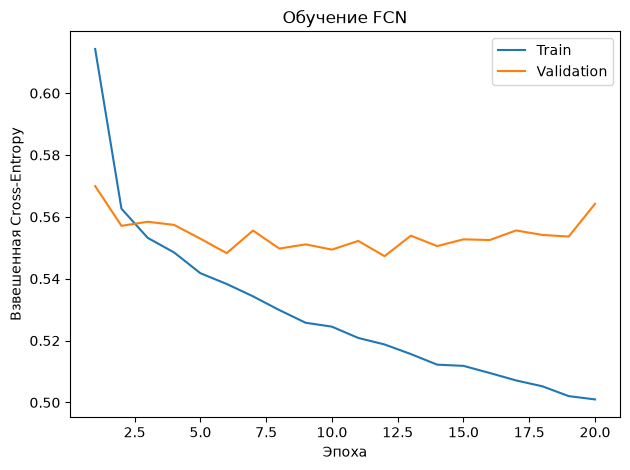

In [13]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение FCN", "Эпоха", "Взвешенная Cross-Entropy")

Снижение обеих кривых указывает на уменьшение ошибки. Рост Validation при дальнейшем падении Train может свидетельствовать о переобучении; выбор весов выполнялся по минимуму Validation.

### Матрица ошибок

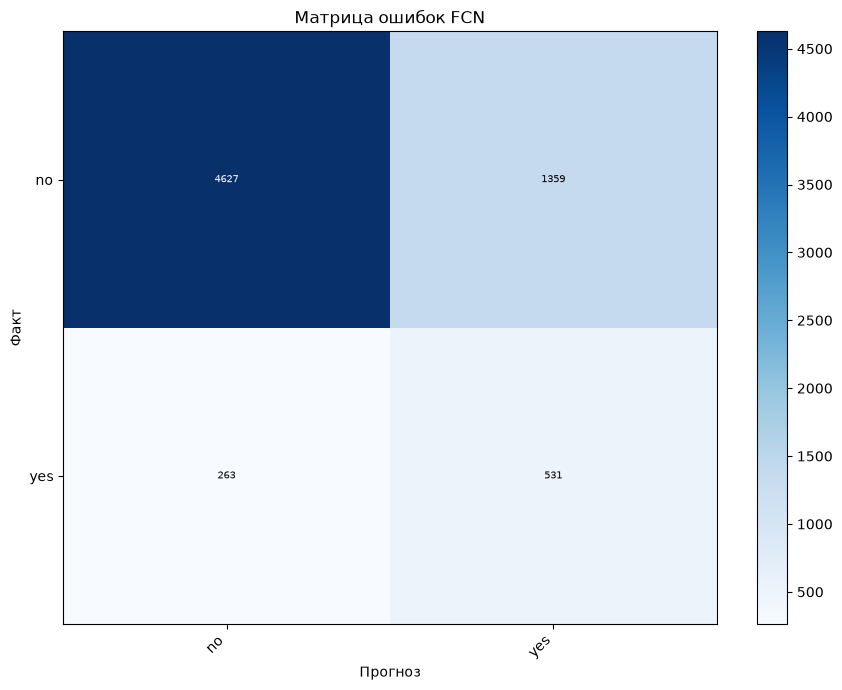

In [14]:
cm=confusion_matrix(true,pred,labels=[0,1]); heat(cm,["no","yes"],"Матрица ошибок FCN", "Прогноз", "Факт", "d")

На диагонали — верные ответы. Верхняя правая клетка — ошибочное предсказание вклада, нижняя левая — пропущенный вклад. Числа дают абсолютное количество ошибок.

### ROC-кривая

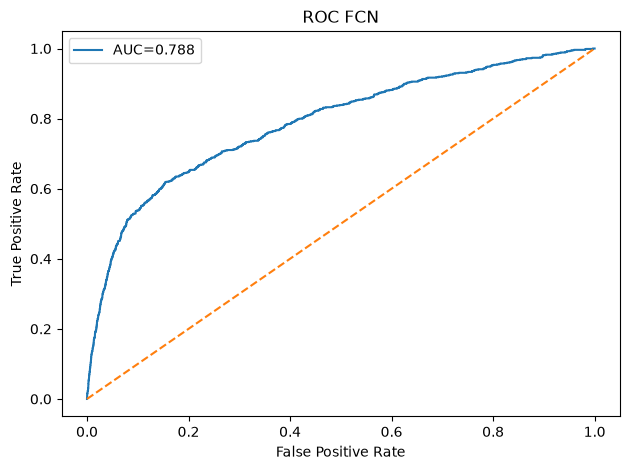

In [15]:
fpr,tpr,_=roc_curve(true,prob); plt.figure(); plt.plot(fpr,tpr,label=f"AUC={m['ROC-AUC']:.3f}"); plt.plot([0,1],[0,1],"--"); plt.legend(); chart("ROC FCN", "False Positive Rate", "True Positive Rate")

Кривая показывает компромисс между долей ложных срабатываний и долей найденных положительных объектов при разных порогах. Чем ближе линия к левому верхнему углу, тем лучше ранжирование.

### Кривая Precision–Recall

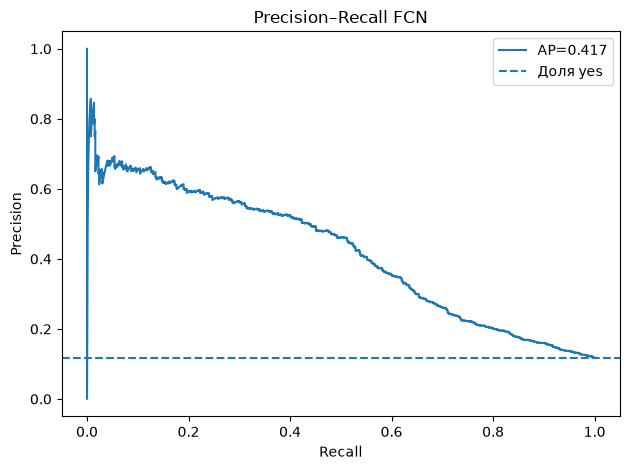

In [16]:
p,r,_=precision_recall_curve(true,prob); plt.figure(); plt.plot(r,p,label=f"AP={m['PR-AUC (AP)']:.3f}"); plt.axhline(true.mean(),ls="--",label="Доля yes"); plt.legend(); chart("Precision–Recall FCN", "Recall", "Precision")

PR-кривая особенно полезна для редкого положительного класса. Пунктир показывает долю положительных объектов, а AP характеризует качество ранжирования по precision и recall.

### Распределение оценок модели

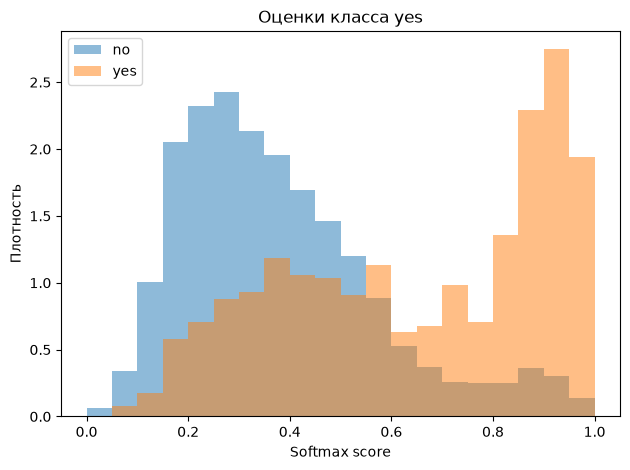

In [17]:
plt.figure();
for k in [0,1]: plt.hist(prob[true==k],bins=np.linspace(0,1,21),density=True,alpha=.5,label=["no","yes"][k])
plt.legend(); chart("Оценки класса yes", "Softmax score", "Плотность")

По оси X — оценка принадлежности к yes, по Y — нормированная плотность. Перекрытие отражает неоднозначные случаи; взвешенная функция потерь может влиять на калибровку вероятностей.

### Метрики по классам

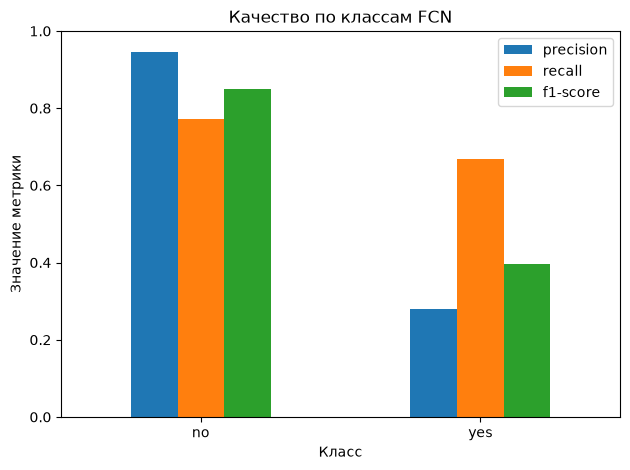

In [18]:
rep=pd.DataFrame(classification_report(true,pred,target_names=["no","yes"],output_dict=True,zero_division=0)).T.loc[["no","yes"],["precision","recall","f1-score"]]; rep.plot.bar(rot=0,ylim=(0,1)); chart("Качество по классам FCN", "Класс", "Значение метрики")

Группы столбцов сравнивают качество для каждого класса. Низкий Recall класса yes означает пропущенные вклады. Macro F1 усредняет F1 классов без учёта их численности.

In [19]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"После очистки для обучения использовано {sizes['Train']} клиентов. Accuracy={m['Accuracy']:.3f}, Macro F1={m['Macro F1']:.3f}, Recall yes={m['Recall (yes)']:.3f}; ROC-AUC={m['ROC-AUC']:.3f}. При дисбалансе следует учитывать полноту класса yes, а не только общую точность."}
print(REPORT["conclusion"])

После очистки для обучения использовано 31636 клиентов. Accuracy=0.761, Macro F1=0.623, Recall yes=0.669; ROC-AUC=0.788. При дисбалансе следует учитывать полноту класса yes, а не только общую точность.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.

# Свёрточная нейронная сеть (CNN)

Цель работы — распознавание десяти видов одежды и обуви по полутоновым изображениям 28×28. Используется полный Fashion-MNIST: 60 000 исходных обучающих и 10 000 тестовых изображений. После проверки изображений выделяется Validation из исходного Train; официальный Test остаётся отдельным.

Источник: [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).

In [20]:
seed_all()
base="https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files={"train-images-idx3-ubyte.gz":"8d4fb7e6c68d591d4c3dfef9ec88bf0d","train-labels-idx1-ubyte.gz":"25c81989df183df01b3e8a0aad5dffbe","t10k-images-idx3-ubyte.gz":"bef4ecab320f06d8554ea6380940ec79","t10k-labels-idx1-ubyte.gz":"bb300cfdad3c16e7a12a480ee83cd310"}
def read_idx(name):
    raw=gzip.decompress(fetch(base+name,name,files[name]).read_bytes())
    magic,count=struct.unpack(">II",raw[:8])
    if magic==2051:
        h,w=struct.unpack(">II",raw[8:16]); assert (h,w)==(28,28)
        return np.frombuffer(raw,dtype=np.uint8,offset=16).reshape(count,h,w).copy()
    assert magic==2049
    return np.frombuffer(raw,dtype=np.uint8,offset=8).reshape(count).copy()
x0=read_idx("train-images-idx3-ubyte.gz"); y0=read_idx("train-labels-idx1-ubyte.gz")
xte=read_idx("t10k-images-idx3-ubyte.gz"); yte=read_idx("t10k-labels-idx1-ubyte.gz")
labels=["Футболка","Брюки","Пуловер","Платье","Пальто","Сандалии","Рубашка","Кроссовки","Сумка","Ботинки"]
print(x0.shape,y0.shape,xte.shape,yte.shape)

Загружен train-images-idx3-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-images-idx3-ubyte.gz (системные CA)


Загружен train-labels-idx1-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-labels-idx1-ubyte.gz (системные CA)


Загружен t10k-images-idx3-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz (системные CA)


Загружен t10k-labels-idx1-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-labels-idx1-ubyte.gz (системные CA)
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


Файлы IDX распаковываются через gzip, затем считывается двоичный заголовок: код 2051 обозначает изображения, 2049 — метки. `reshape` восстанавливает размер 28×28. Контрольные суммы проверяются перед чтением. На экране появляются формы массивов; метки представлены числами 0–9.

In [21]:
def clean_images(x,y):
    assert len(x)==len(y)
    valid=(y<10)&(x.max(axis=(1,2))>x.min(axis=(1,2)))
    print("Некорректные/однотонные:",int((~valid).sum()),"NaN:",int(np.isnan(x).sum()),"Пиксели:",x.min(),x.max())
    x,y=x[valid],y[valid]
    _, idx, counts=np.unique(x.reshape(len(x),-1),axis=0,return_index=True,return_counts=True)
    print("Повторные изображения:",int(len(x)-len(idx)))
    # Все совпадающие изображения исключены, в том числе с разными метками.
    idx=np.sort(idx[counts==1]); return x[idx],y[idx]
x0,y0=clean_images(x0,y0); xte,yte=clean_images(xte,yte)
# Не допускается совпадение пикселей между Train/Validation и Test.
test_keys={v.tobytes() for v in xte}; keep=np.array([v.tobytes() not in test_keys for v in x0]); print("Совпадения с Test:",int((~keep).sum()))
x0,y0=x0[keep],y0[keep]
i,j=train_test_split(np.arange(len(y0)),test_size=.15,stratify=y0,random_state=42)
xa,ya=x0[i],y0[i]; xb,yb=x0[j],y0[j]
sizes=size_table(len(xa),len(xb),len(xte)); print(sizes)
# Фиксированное преобразование, не оценивает параметры на Test.
a=xa[:,None].astype(np.float32)/255; b=xb[:,None].astype(np.float32)/255; c=xte[:,None].astype(np.float32)/255

Некорректные/однотонные: 0 NaN: 0 Пиксели: 0 255


Повторные изображения: 0
Некорректные/однотонные: 0 NaN: 0 Пиксели: 0 255


Повторные изображения: 0
Совпадения с Test: 0
{'Train': 51000, 'Validation': 9000, 'Test': 10000}


Проверены диапазон пикселей, NaN, соответствие числа меток, классы, однотонные и одинаковые изображения. Повторяющиеся изображения исключены, а совпадения с Test убраны из исходной обучающей части. `train_test_split` сохраняет доли классов при выделении 15% на Validation. Деление на 255 переводит пиксели из 0–255 в 0–1, `[:,None]` добавляет канал. Печатается фактический размер каждой выборки.

### Примеры изображений

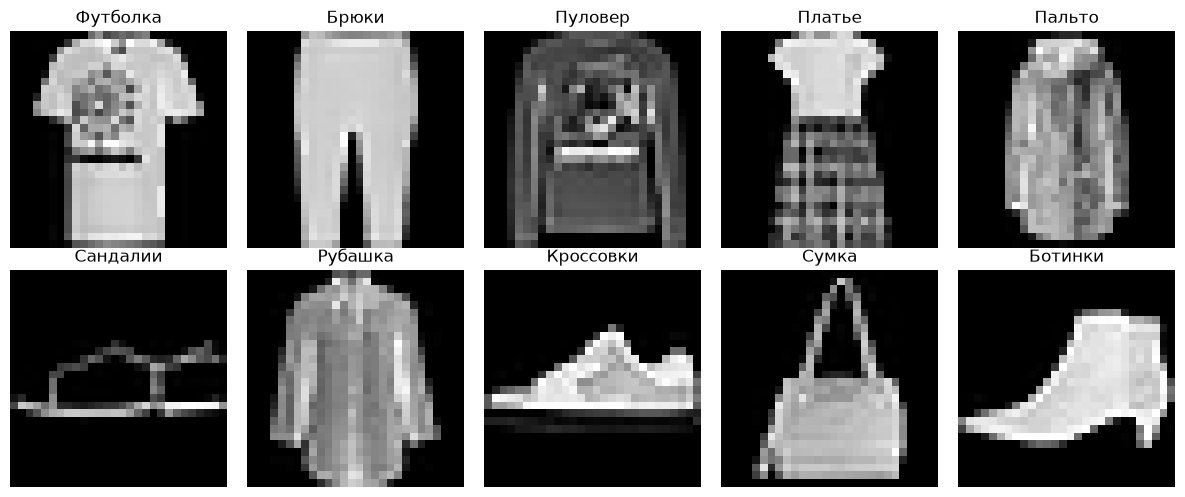

In [22]:
fig,axes=plt.subplots(2,5,figsize=(12,5));
for k,ax in enumerate(axes.ravel()):
    ax.imshow(xa[np.flatnonzero(ya==k)[0]],cmap="gray",vmin=0,vmax=255); ax.set_title(labels[k]); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()

Показано по одному изображению каждого класса из Train. Светлые пиксели соответствуют большей интенсивности. Некоторые категории, например рубашка и футболка, имеют сходные контуры, что может приводить к ошибкам.

### Распределение классов

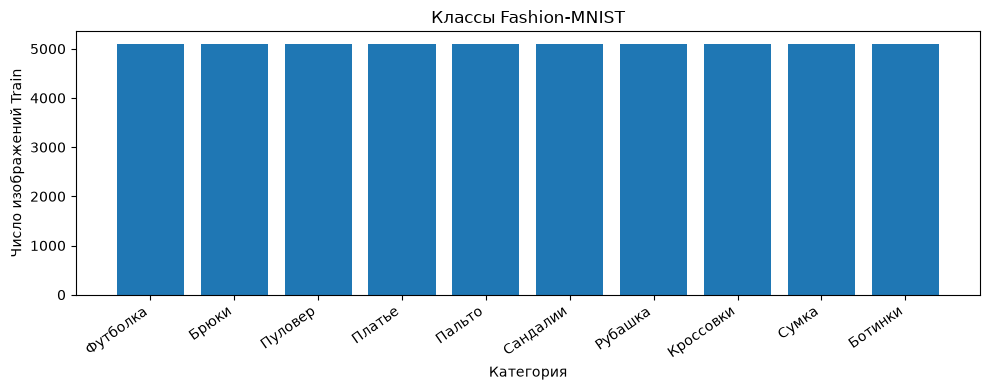

In [23]:
plt.figure(figsize=(10,4)); plt.bar(labels,np.bincount(ya,minlength=10)); plt.xticks(rotation=35,ha="right"); chart("Классы Fashion-MNIST", "Категория", "Число изображений Train")

Высота каждого столбца — число обучающих изображений данной категории после очистки. Сравниваются доли классов; если они почти одинаковы, общая Accuracy более информативна, но индивидуальные метрики всё равно необходимы.

### Гистограмма интенсивности пикселей

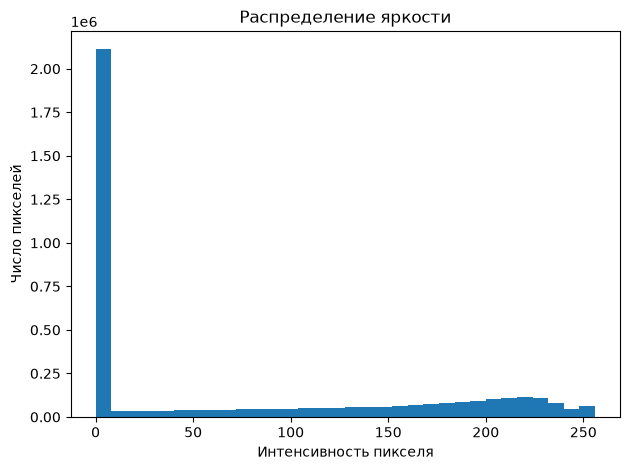

In [24]:
plt.figure(); plt.hist(xa[::10].ravel(),bins=32,range=(0,256)); chart("Распределение яркости", "Интенсивность пикселя", "Число пикселей")

Для читаемости взят каждый десятый обучающий образец; все изображения участвуют в обучении. Ось X показывает яркость, ось Y — количество пикселей. Большой столбец около нуля связан с тёмным фоном.

### Средние изображения классов

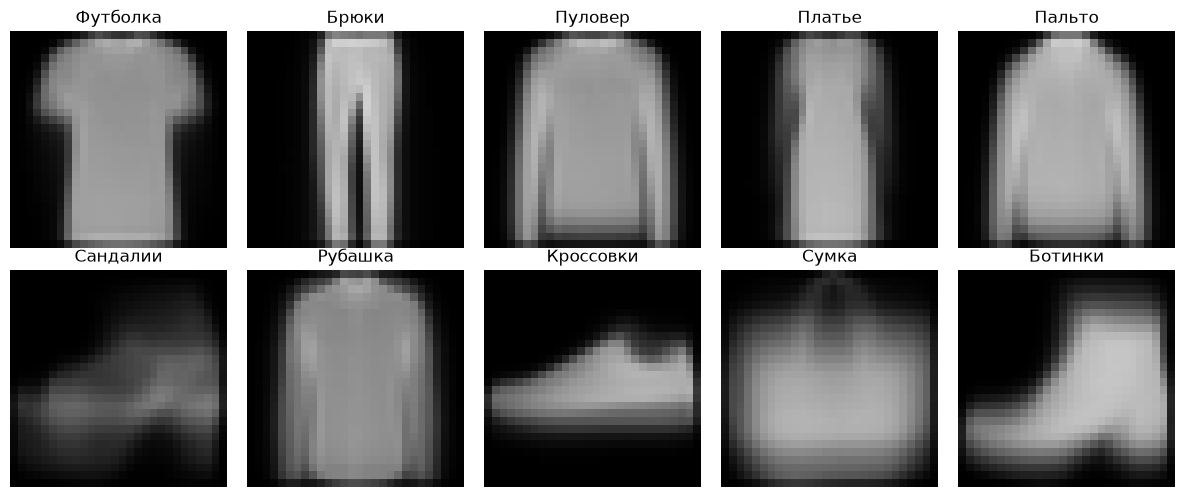

In [25]:
fig,axes=plt.subplots(2,5,figsize=(12,5));
for k,ax in enumerate(axes.ravel()):
    ax.imshow(xa[ya==k].mean(0),cmap="gray",vmin=0,vmax=255); ax.set_title(labels[k]); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()

Для каждого класса рассчитано среднее изображение по всем его обучающим примерам. Яркие области показывают места, где предмет встречается чаще; размытость возникает из-за различий формы и положения.

### Диаграмма размаха яркости

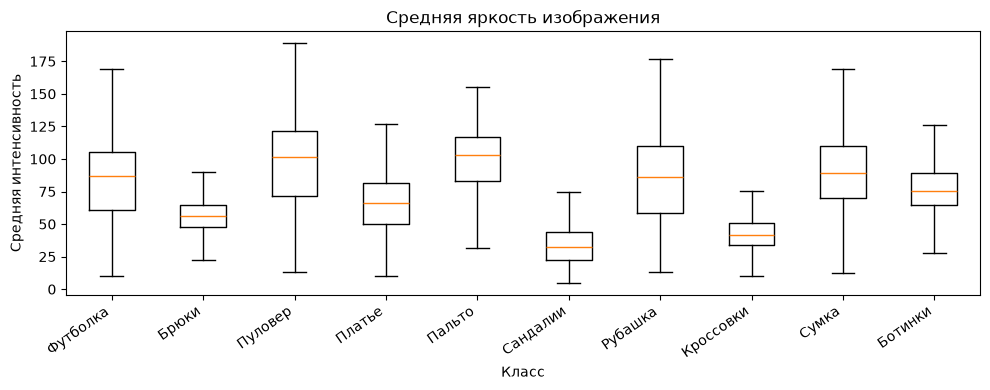

In [26]:
brightness=xa.mean(axis=(1,2)); plt.figure(figsize=(10,4)); plt.boxplot([brightness[ya==k] for k in range(10)],tick_labels=labels,showfliers=False); plt.xticks(rotation=35,ha="right"); chart("Средняя яркость изображения", "Класс", "Средняя интенсивность")

Линия в коробке — медиана средней яркости изображения, границы — квартили. Усы отражают разброс; крайние точки скрыты исключительно для читаемости, данные не удаляются. Категории могут отличаться площадью светлых областей.

### Корреляция характеристик изображений

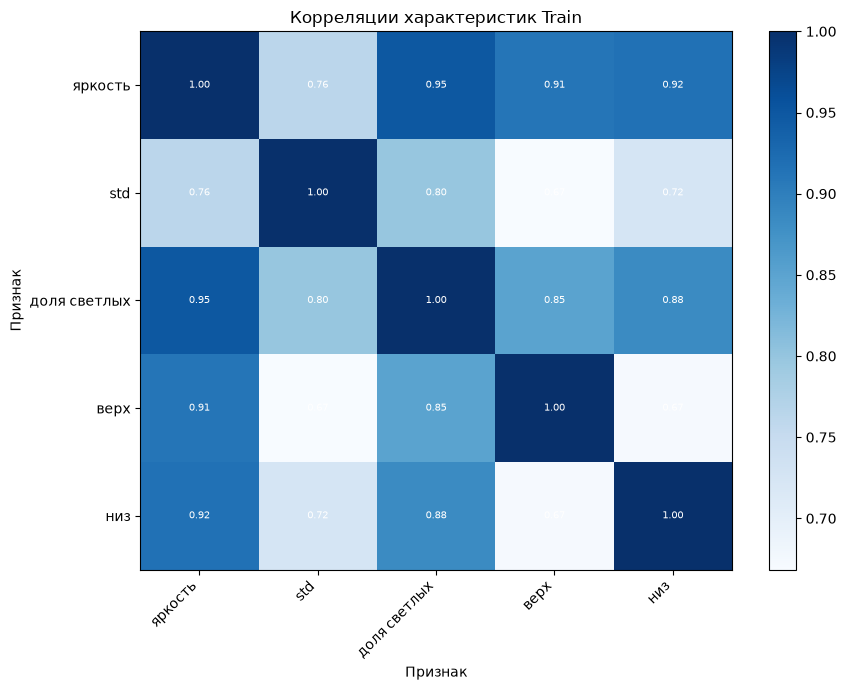

In [27]:
desc=pd.DataFrame({"яркость":brightness,"std":xa.std(axis=(1,2)),"доля светлых":(xa>128).mean(axis=(1,2)),"верх":xa[:,:14].mean(axis=(1,2)),"низ":xa[:,14:].mean(axis=(1,2))}); corr=desc.corr(); heat(corr,corr.columns,"Корреляции характеристик Train", "Признак", "Признак", ".2f")

Матрица Пирсона показывает линейные связи между агрегированными характеристиками, например средней яркостью и долей светлых пикселей. Эти характеристики предназначены только для анализа; CNN получает исходные пиксельные массивы.

In [28]:
train=loader(a,ya,batch=128,shuffle=True); val=loader(b,yb,batch=256); test=loader(c,yte,batch=256)
model=nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),nn.Linear(32*7*7,64),nn.ReLU(),nn.Linear(64,10))
loss_fn=nn.CrossEntropyLoss(); print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=12,lr=.001)
_, logits,true=evaluate(model,test,loss_fn); pred=logits.argmax(1); probs=torch.softmax(torch.tensor(logits),dim=1).numpy()
m=class_metrics(true,pred); print(m); print(classification_report(true,pred,target_names=labels,zero_division=0))

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=10, bias=True)
)
Параметров: 105866


Epoch 01: train loss=0.6618; val loss=0.4181; val score=0.8523


Epoch 02: train loss=0.4113; val loss=0.3576; val score=0.8698


Epoch 03: train loss=0.3524; val loss=0.3110; val score=0.8901


Epoch 04: train loss=0.3237; val loss=0.3225; val score=0.8839


Epoch 05: train loss=0.2994; val loss=0.2833; val score=0.8977


... (4 outputs left out)

Epoch 10: train loss=0.2331; val loss=0.2548; val score=0.9076


Epoch 11: train loss=0.2237; val loss=0.2370; val score=0.9157


Epoch 12: train loss=0.2131; val loss=0.2279; val score=0.9176


{'Accuracy': 0.9061, 'Macro Precision': 0.906417465484832, 'Macro Recall': 0.9061, 'Macro F1': 0.9058709428249966}
              precision    recall  f1-score   support

    Футболка       0.86      0.85      0.85      1000
       Брюки       0.99      0.97      0.98      1000
     Пуловер       0.88      0.84      0.86      1000
      Платье       0.90      0.90      0.90      1000
      Пальто       0.81      0.89      0.85      1000
    Сандалии       0.98      0.97      0.98      1000
     Рубашка       0.76      0.72      0.74      1000
   Кроссовки       0.93      0.98      0.96      1000
       Сумка       0.97      0.98      0.98      1000
     Ботинки       0.98      0.95      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



`Conv2d` применяет обучаемые ядра 3×3 к локальным областям. Два слоя формируют 16 и 32 карты признаков, MaxPool2d уменьшает пространственный размер 28→14→7. `Flatten` разворачивает карты, полносвязные слои выдают 10 логитов. CrossEntropyLoss принимает логиты и метки классов. В выводе показывается архитектура, число параметров, история 12 эпох и отчёт на официальном очищенном Test. Accuracy — доля правильных ответов; Macro Precision, Recall и F1 — средние по десяти классам.

### Кривые функции потерь

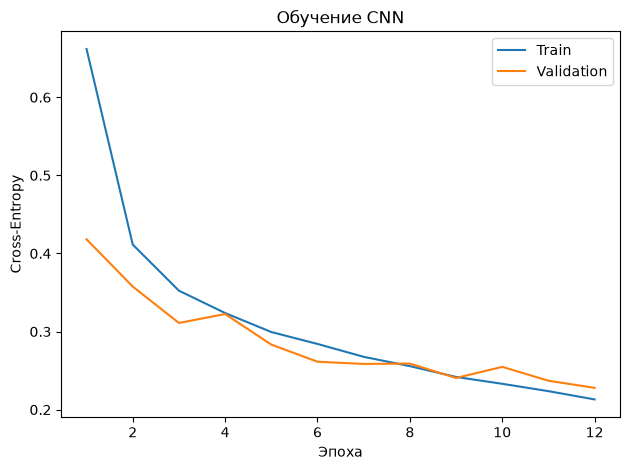

In [29]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение CNN", "Эпоха", "Cross-Entropy")

По оси X — эпохи, по Y — средняя ошибка. Разница между Train и Validation помогает обнаружить переобучение. Для Test использовано состояние с минимальной ошибкой Validation.

### Кривая точности валидации

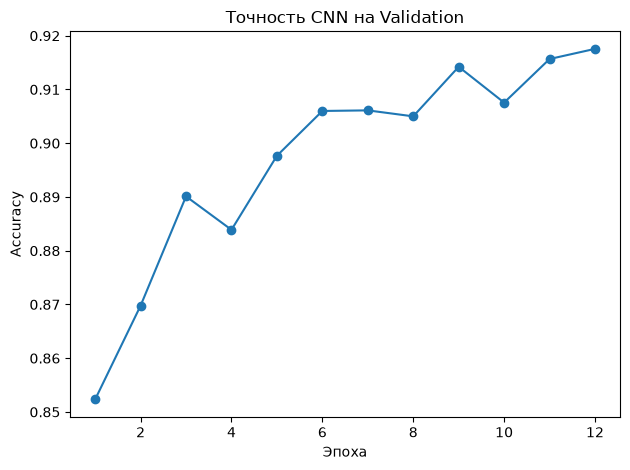

In [30]:
plt.figure(); plt.plot(history.epoch,history.val_score,marker="o"); chart("Точность CNN на Validation", "Эпоха", "Accuracy")

Каждая точка показывает долю верных предсказаний на Validation после эпохи. Рост и дальнейшее плато отражают изменение качества; это не тестовая метрика.

### Матрица ошибок

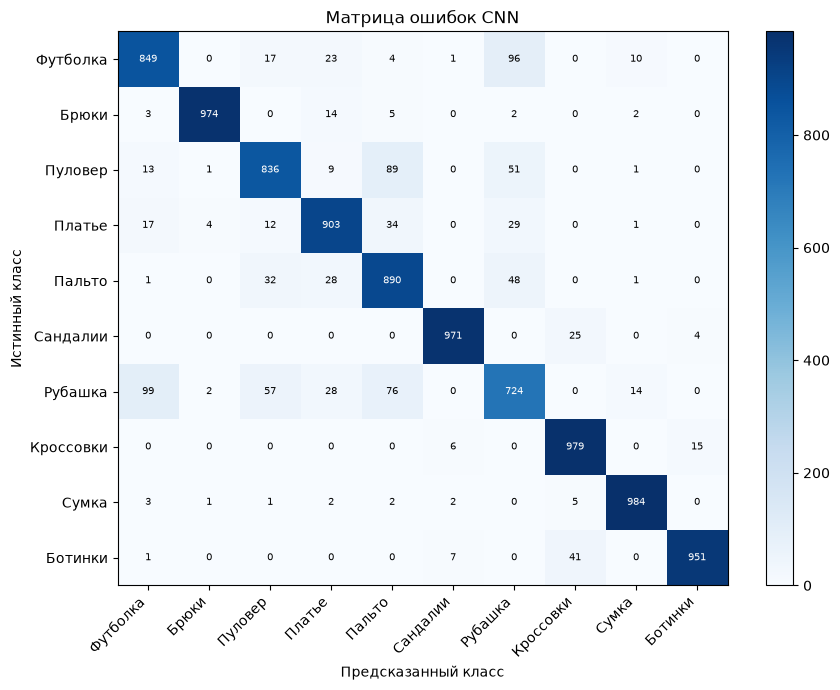

In [31]:
cm=confusion_matrix(true,pred,labels=np.arange(10)); heat(cm,labels,"Матрица ошибок CNN", "Предсказанный класс", "Истинный класс", "d")

Строки — фактические классы, столбцы — прогноз. Диагональ содержит правильные ответы, остальные ячейки показывают, какие категории сеть путает.

### Метрики по классам

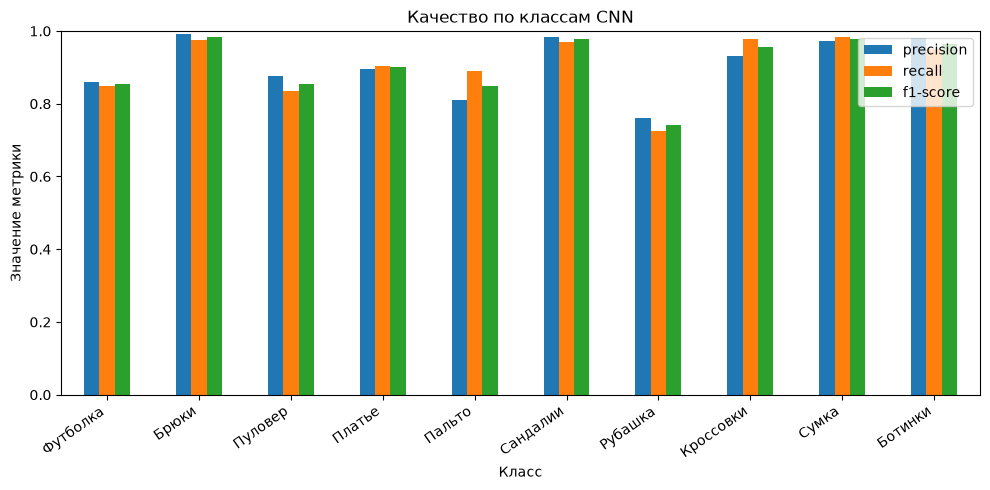

In [32]:
rep=pd.DataFrame(classification_report(true,pred,target_names=labels,output_dict=True,zero_division=0)).T.loc[labels,["precision","recall","f1-score"]]; rep.plot.bar(figsize=(10,5),ylim=(0,1)); plt.xticks(rotation=35,ha="right"); chart("Качество по классам CNN", "Класс", "Значение метрики")

По трём столбцам для каждого класса сопоставляются полнота, точность и F1. Macro F1 не позволяет частому или лёгкому классу скрыть низкое качество остальных.

### Примеры ошибок классификации

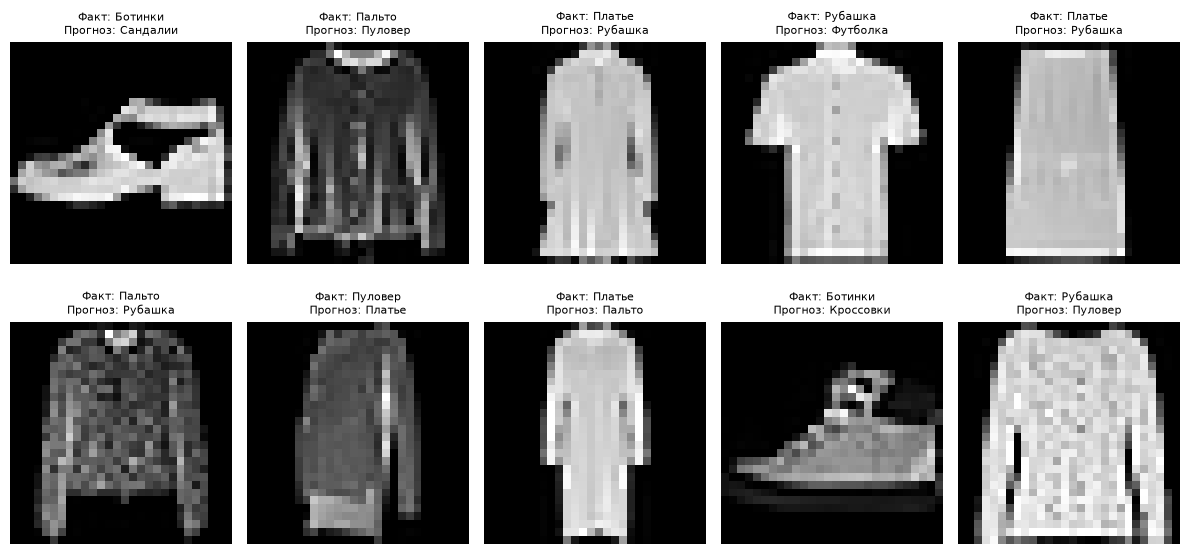

In [33]:
bad=np.flatnonzero(true!=pred); fig,axes=plt.subplots(2,5,figsize=(12,6));
for ax in axes.ravel(): ax.axis("off")
for index,ax in zip(bad[:10],axes.ravel()):
    ax.imshow(xte[index],cmap="gray"); ax.set_title(f"Факт: {labels[true[index]]}\nПрогноз: {labels[pred[index]]}",fontsize=8)
if len(bad)==0: fig.suptitle("Ошибок на Test нет")
plt.tight_layout(); plt.show(); plt.close()

Показаны первые десять ошибочных предсказаний Test, если такие имеются. Подписи сравнивают реальные и предсказанные категории. По контурам можно увидеть возможные причины путаницы, но это не доказывает причину ошибки.

### Распределение уверенности

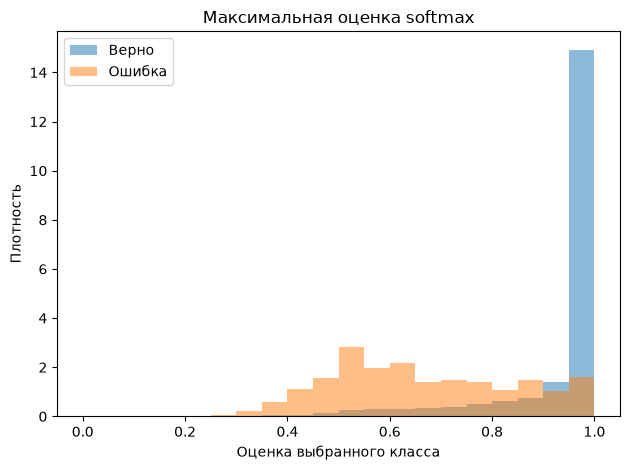

In [34]:
conf=probs.max(1); plt.figure();
for mask,label in [(true==pred,"Верно"),(true!=pred,"Ошибка")]:
    if mask.any(): plt.hist(conf[mask],bins=np.linspace(0,1,21),alpha=.5,density=True,label=label)
plt.legend(); chart("Максимальная оценка softmax", "Оценка выбранного класса", "Плотность")

Максимум softmax — оценка уверенности в выбранном классе. Сопоставляются распределения для верных и ошибочных ответов. Высокая оценка не гарантирует правильность, а softmax сам по себе не является доказательством калибровки.

In [35]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"Для обучения CNN использовано {sizes['Train']} отдельных изображений. На Test получены Accuracy={m['Accuracy']:.3f} и Macro F1={m['Macro F1']:.3f}. Матрица ошибок и метрики по классам позволяют оценить различия в распознавании категорий."}
print(REPORT["conclusion"])

Для обучения CNN использовано 51000 отдельных изображений. На Test получены Accuracy=0.906 и Macro F1=0.906. Матрица ошибок и метрики по классам позволяют оценить различия в распознавании категорий.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.

# Рекуррентная нейронная сеть (RNN)

Цель — прогноз температуры воздуха на один час вперёд по метеорологическим измерениям за предыдущие 24 часа. Исходный ряд содержит около 420 тыс. десятиминутных измерений; для работы формируются средние часовые значения. Разбиение хронологическое, без случайного перемешивания временных интервалов.

Источник: [Jena Climate / Keras](https://keras.io/examples/timeseries/timeseries_weather_forecasting/).

In [36]:
seed_all()
path=fetch("https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip","jena_climate.zip")
with zipfile.ZipFile(path) as z: df=pd.read_csv(z.open(next(x for x in z.namelist() if x.endswith(".csv"))))
print("Исходный размер:",df.shape); display(df.head()); df.info()
cols=["T (degC)","p (mbar)","rh (%)","wv (m/s)","Tdew (degC)"]
dates=pd.to_datetime(df["Date Time"],format="%d.%m.%Y %H:%M:%S",errors="coerce")
v=df[cols].apply(pd.to_numeric,errors="coerce"); v.index=dates
print("Пропуски:"); display(v.isna().sum()); print("Дубликаты времени:",int(v.index.duplicated().sum()))
print("Некорректные даты:",int(v.index.isna().sum()))
print("Описательная статистика:"); display(v.describe().T)
valid=(v["T (degC)"].between(-60,60)&v["p (mbar)"].between(800,1100)&v["rh (%)"].between(0,100)&v["wv (m/s)"].between(0,100)&v["Tdew (degC)"].between(-80,60))
print("Некорректные значения:",int((~valid).sum()))
v.loc[~valid.to_numpy(),:]=np.nan
v=v.loc[~v.index.isna()].sort_index(); v=v.loc[~v.index.duplicated(keep="first")]
hour=v.resample("1h").mean(); count=v.resample("1h").count().min(axis=1); hour.loc[count<3]=np.nan
print("Часов:",len(hour),"Неполных часов:",int(hour.isna().any(axis=1).sum()))

Загружен jena_climate.zip: https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip (системные CA)


Исходный размер: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  object 
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), object(1)
memory usage: 48.1+ MB


Пропуски:


T (degC)       0
p (mbar)       0
rh (%)         0
wv (m/s)       0
Tdew (degC)    0
dtype: int64

Дубликаты времени: 327
Некорректные даты: 0
Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
T (degC),420551.0,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
p (mbar),420551.0,989.212776,8.358481,913.60,984.20,989.58,994.72,1015.35
rh (%),420551.0,76.008259,16.476175,12.95,65.21,79.30,89.40,100.00
wv (m/s),420551.0,1.702224,65.446714,-9999.00,0.99,1.76,2.86,28.49
Tdew (degC),420551.0,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11


Некорректные значения: 18


Часов: 70129 Неполных часов: 94


В CSV проверены метки времени, повторения, пропуски и физически допустимые диапазоны пяти выбранных величин; служебные значения вроде отрицательной скорости ветра исключаются. `resample("1h").mean()` усредняет измерения за час. Если наблюдений меньше трёх, час считается неполным. Неполные часы не интерполируются будущими значениями. В выводе приведены формы, статистика и число исключённых наблюдений.

In [37]:
n=len(hour); t1=int(n*.70); t2=int(n*.85)
blocks=[hour.iloc[:t1],hour.iloc[t1:t2],hour.iloc[t2:]]
scaler=StandardScaler().fit(blocks[0].dropna())
def windows(block):
    x=scaler.transform(block).astype(np.float32); steps=24
    w=np.lib.stride_tricks.sliding_window_view(x,steps+1,axis=0).transpose(0,2,1)
    mask=np.isfinite(w).all(axis=(1,2)); w=w[mask]
    return w[:,:steps].copy(),w[:,steps,0:1].copy(),block.index[steps:][mask]
a,ya,ta=windows(blocks[0]); b,yb,tb=windows(blocks[1]); c,yc,tc=windows(blocks[2])
sizes=size_table(len(a),len(b),len(c)); print(sizes); print("Форма Train:",a.shape,ya.shape)
print("Границы:",ta[0],ta[-1],tb[0],tb[-1],tc[0],tc[-1])
eda=blocks[0].dropna(); cal=blocks[0]["T (degC)"]
q1,q3=eda.quantile(.25),eda.quantile(.75); iqr=q3-q1; display(((eda<q1-1.5*iqr)|(eda>q3+1.5*iqr)).sum().to_frame("IQR"))

{'Train': 49066, 'Validation': 10428, 'Test': 10397}
Форма Train: (49066, 24, 5) (49066, 1)
Границы: 2009-01-02 00:00:00 2014-08-08 09:00:00 2014-08-09 10:00:00 2015-10-20 16:00:00 2015-10-21 17:00:00 2016-12-31 23:00:00


,IQR
T (degC),174
p (mbar),772
rh (%),78
wv (m/s),1616
Tdew (degC),371


Сначала данные разделены по времени в пропорции 70/15/15, затем StandardScaler обучен исключительно на полных часах Train. `sliding_window_view` создаёт окна из 25 часов: первые 24 — вход, 25-й — целевая температура. Окна с пропусками исключены, границы выборок не пересекаются. Печатаются размеры и диапазоны дат, а IQR-таблица показывает потенциальные крайние значения Train; редкие погодные значения не удаляются автоматически. Окна внутри выборки перекрываются, поэтому это не независимые наблюдения.

### График временного ряда

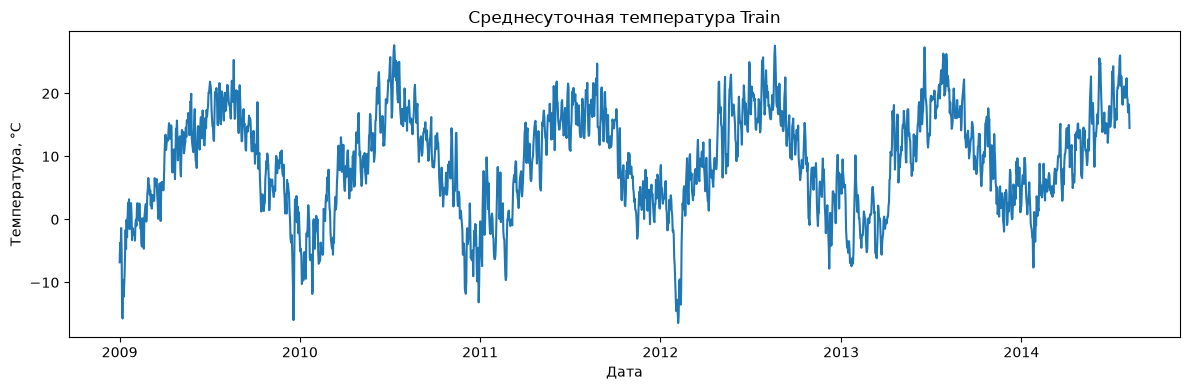

In [38]:
plt.figure(figsize=(12,4)); plt.plot(cal.resample("1D").mean()); chart("Среднесуточная температура Train", "Дата", "Температура, °C")

Линия показывает среднюю температуру каждого дня обучающего периода. Повторение подъёмов и спадов отражает годовую сезонность. Дневное усреднение применяется только для визуализации.

### Гистограмма температуры

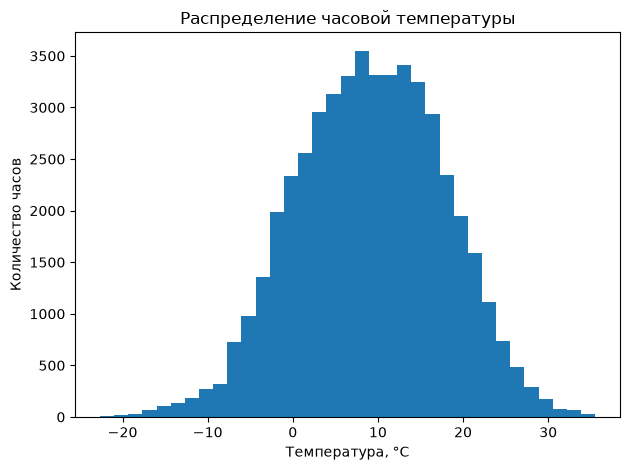

In [39]:
plt.figure(); plt.hist(eda["T (degC)"],bins=35); chart("Распределение часовой температуры", "Температура, °C", "Количество часов")

Высота столбца — число часов в заданном диапазоне температуры. По форме распределения судят о частых значениях и редких экстремумах.

### Диаграмма размаха по месяцам

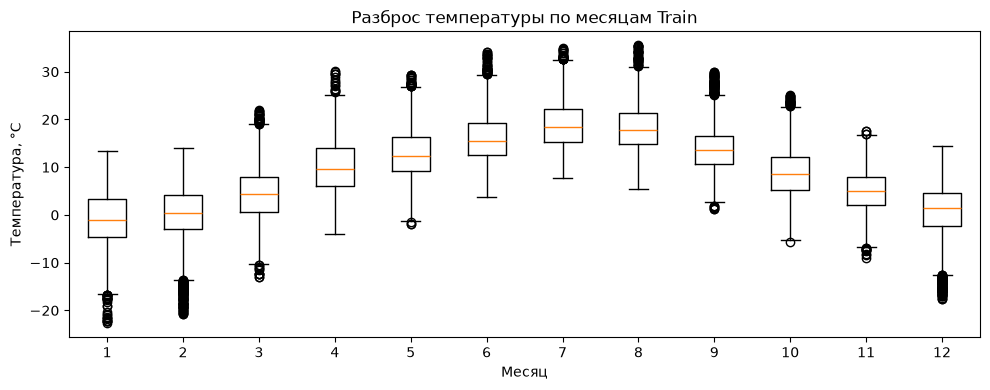

In [40]:
plt.figure(figsize=(10,4)); plt.boxplot([eda.loc[eda.index.month==k,"T (degC)"] for k in range(1,13)],tick_labels=list(range(1,13))); chart("Разброс температуры по месяцам Train", "Месяц", "Температура, °C")

Каждая коробка характеризует центральные 50% температур данного месяца, центральная линия — медиана. Усы и точки отображают разброс температур; различие медиан характеризует сезонность.

### Суточный профиль

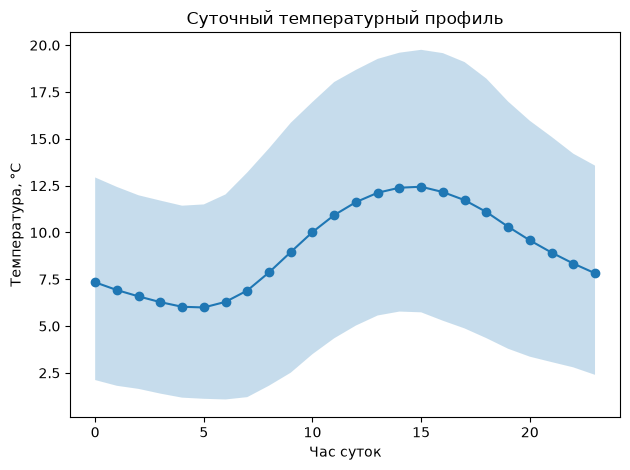

In [41]:
g=eda["T (degC)"].groupby(eda.index.hour); plt.figure(); plt.plot(g.mean(),marker="o"); plt.fill_between(np.arange(24),g.quantile(.25).values,g.quantile(.75).values,alpha=.25); chart("Суточный температурный профиль", "Час суток", "Температура, °C")

Линия соответствует средней температуре в каждый час суток, полоса — межквартильный диапазон. Часть изменения связана с суточным циклом; ширина полосы отражает сезонный и погодный разброс.

### Автокорреляционная функция

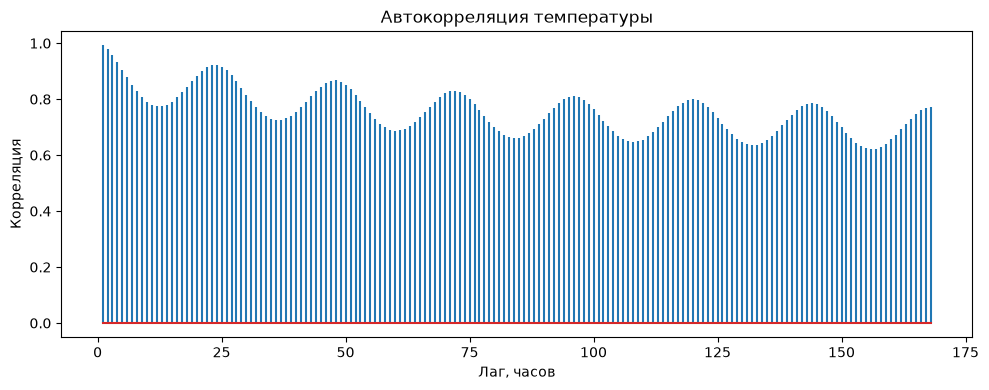

In [42]:
plt.figure(figsize=(10,4)); lags=np.arange(1,169); ac=[cal.autocorr(int(k)) for k in lags]; plt.stem(lags,ac,markerfmt=" "); chart("Автокорреляция температуры", "Лаг, часов", "Корреляция")

Для каждой задержки рассчитывается корреляция ряда с собственной сдвинутой копией. Пики на кратных 24 часам могут указывать на суточную периодичность. Используется только Train; пропуски учитываются попарно.

### Корреляционная матрица

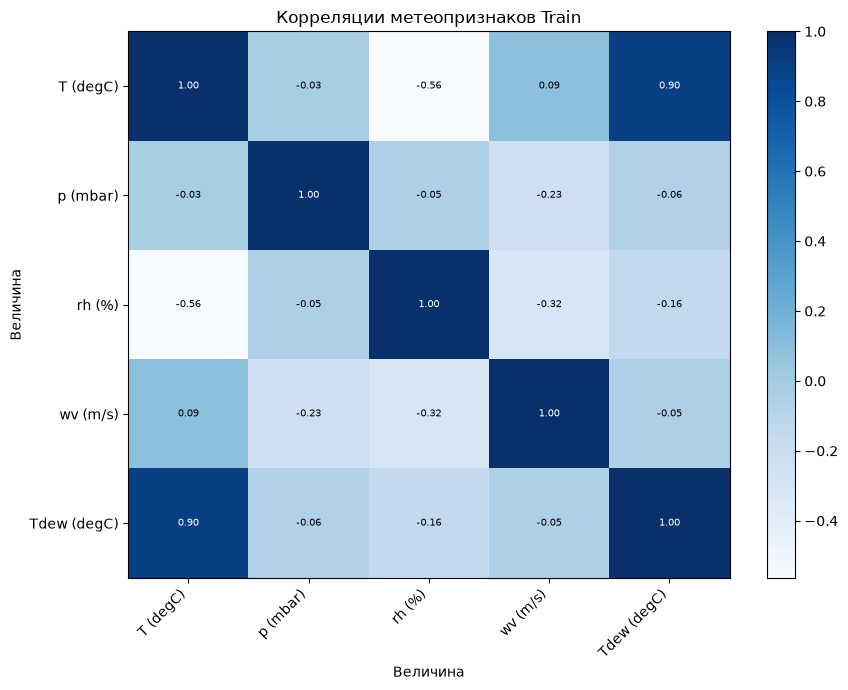

In [43]:
corr=eda.corr(); heat(corr,corr.columns,"Корреляции метеопризнаков Train", "Величина", "Величина", ".2f")

Ячейки показывают коэффициенты Пирсона между пятью погодными величинами. Корреляция описывает линейную связь, но не причинность. Сильная связь температуры и точки росы физически закономерна.

In [44]:
train=loader(a,ya,batch=256,shuffle=True,regression=True); val=loader(b,yb,regression=True); test=loader(c,yc,regression=True)
class WeatherRNN(nn.Module):
    def __init__(self):
        super().__init__(); self.rnn=nn.RNN(input_size=5,hidden_size=32,batch_first=True); self.out=nn.Linear(32,1)
    def forward(self,x):
        _,h=self.rnn(x); return self.out(h[-1])
model=WeatherRNN(); loss_fn=nn.MSELoss(); print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=20,lr=.001,regression=True)
_,p,y=evaluate(model,test,loss_fn,regression=True)
true=y.ravel()*scaler.scale_[0]+scaler.mean_[0]; pred=p.ravel()*scaler.scale_[0]+scaler.mean_[0]
baseline=c[:,-1,0]*scaler.scale_[0]+scaler.mean_[0]
err=true-pred
m={"MAE (°C)":mean_absolute_error(true,pred),"RMSE (°C)":float(np.sqrt(mean_squared_error(true,pred))),"R2":r2_score(true,pred),"Baseline MAE (°C)":mean_absolute_error(true,baseline),"Baseline RMSE (°C)":float(np.sqrt(mean_squared_error(true,baseline)))}
print(m); display(pd.DataFrame({"Дата":tc,"Факт":true,"Прогноз":pred,"Остаток":err}).head(10))

WeatherRNN(
  (rnn): RNN(5, 32, batch_first=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)
Параметров: 1281


Epoch 01: train loss=0.1499; val loss=0.0236; val score=0.1537


Epoch 02: train loss=0.0173; val loss=0.0147; val score=0.1214


Epoch 03: train loss=0.0121; val loss=0.0112; val score=0.1058


Epoch 04: train loss=0.0096; val loss=0.0094; val score=0.0969


Epoch 05: train loss=0.0081; val loss=0.0080; val score=0.0897


... (12 outputs left out)

Epoch 18: train loss=0.0047; val loss=0.0049; val score=0.0701


Epoch 19: train loss=0.0048; val loss=0.0049; val score=0.0698


Epoch 20: train loss=0.0047; val loss=0.0048; val score=0.0695
{'MAE (°C)': 0.3929218305195553, 'RMSE (°C)': 0.5615763014447517, 'R2': 0.994831419646197, 'Baseline MAE (°C)': 0.6474964704250137, 'Baseline RMSE (°C)': 0.9048572345291271}


,Дата,Факт,Прогноз,Остаток
0,2015-10-21 17:00:00,8.990000,9.099606,-0.109606
1,2015-10-21 18:00:00,8.568333,8.599665,-0.031332
2,2015-10-21 19:00:00,8.083333,8.289902,-0.206569
3,2015-10-21 20:00:00,7.691667,7.748944,-0.057277
4,2015-10-21 21:00:00,6.891667,7.375094,-0.483427
5,2015-10-21 22:00:00,6.256667,6.193341,0.063326
6,2015-10-21 23:00:00,5.671667,5.837045,-0.165378
7,2015-10-22 00:00:00,5.365000,5.328771,0.036229
8,2015-10-22 01:00:00,4.940000,5.267944,-0.327944
9,2015-10-22 02:00:00,4.471667,4.703216,-0.231549


`nn.RNN` последовательно обрабатывает 24 временных шага, обновляя скрытое состояние из 32 нейронов. Последнее состояние `h[-1]` поступает в линейный выход. Батчи окон перемешиваются только внутри Train, порядок часов внутри окна остаётся прежним. MSE применяется к стандартизированной температуре; после обучения прогноз возвращён в °C. MAE показывает средний модуль ошибки, RMSE сильнее реагирует на крупные ошибки, R² сравнивает результат с постоянным прогнозом среднего Test. Baseline — последнее известное значение температуры. Вывод содержит архитектуру, историю обучения, метрики и первые десять фактических/предсказанных значений.

### Кривые функции потерь

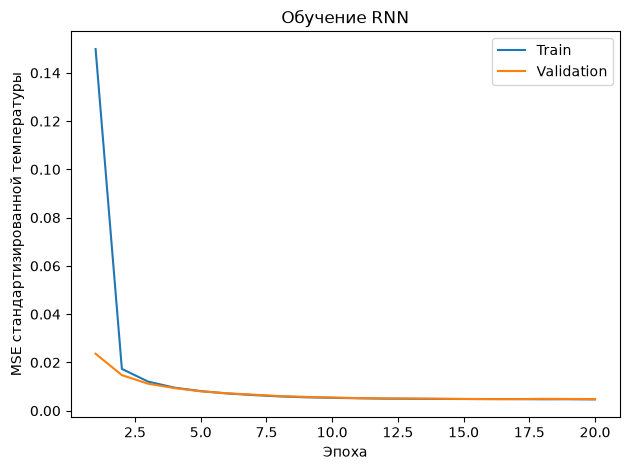

In [45]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение RNN", "Эпоха", "MSE стандартизированной температуры")

Кривые ошибки показывают, как меняется качество в процессе обучения. Выбор состояния сети производится по минимуму Validation MSE; Test не используется при подборе весов.

### Сопоставление прогнозов с фактом

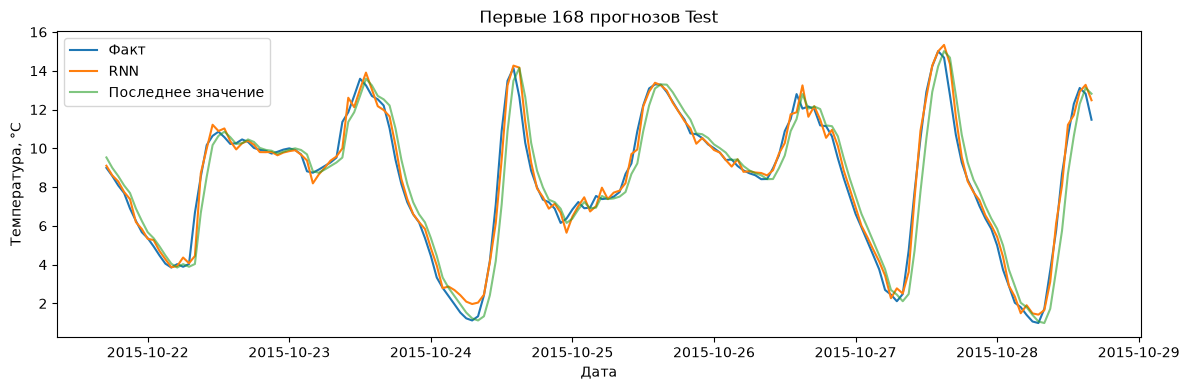

In [46]:
plt.figure(figsize=(12,4)); k=min(168,len(tc)); plt.plot(tc[:k],true[:k],label="Факт"); plt.plot(tc[:k],pred[:k],label="RNN"); plt.plot(tc[:k],baseline[:k],label="Последнее значение",alpha=.6); plt.legend(); chart("Первые 168 прогнозов Test", "Дата", "Температура, °C")

На графике показан начальный участок тестовых прогнозов. Совпадение линий отражает точность, а заметный сдвиг может указывать на запаздывание. Базовый прогноз позволяет оценить вклад сети по сравнению с простым правилом.

### Диаграмма фактических и предсказанных значений

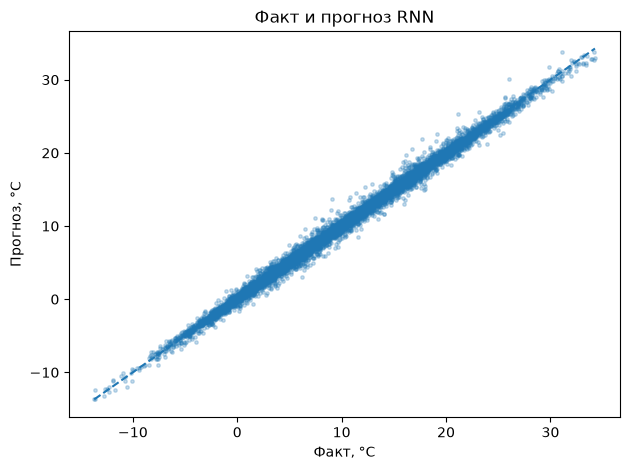

In [47]:
plt.figure(); plt.scatter(true,pred,s=6,alpha=.25); lo=min(true.min(),pred.min()); hi=max(true.max(),pred.max()); plt.plot([lo,hi],[lo,hi],"--"); chart("Факт и прогноз RNN", "Факт, °C", "Прогноз, °C")

Каждая точка соответствует тестовому окну. Диагональ означает идеальное совпадение. Чем ближе облако к диагонали, тем меньше ошибка; отклонения выявляют систематические промахи при отдельных температурах.

### Гистограмма остатков

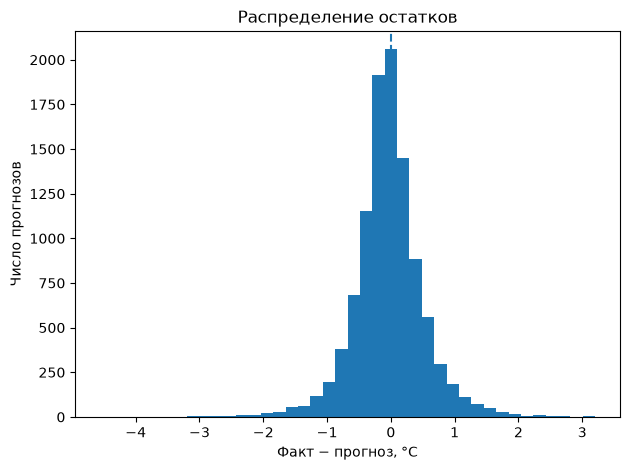

In [48]:
plt.figure(); plt.hist(err,bins=40); plt.axvline(0,ls="--"); chart("Распределение остатков", "Факт − прогноз, °C", "Число прогнозов")

Положительный остаток означает занижение прогноза, отрицательный — завышение. Концентрация около нуля и симметрия дают представление о систематической ошибке; длинные хвосты показывают крупные промахи.

### Диаграмма остатков

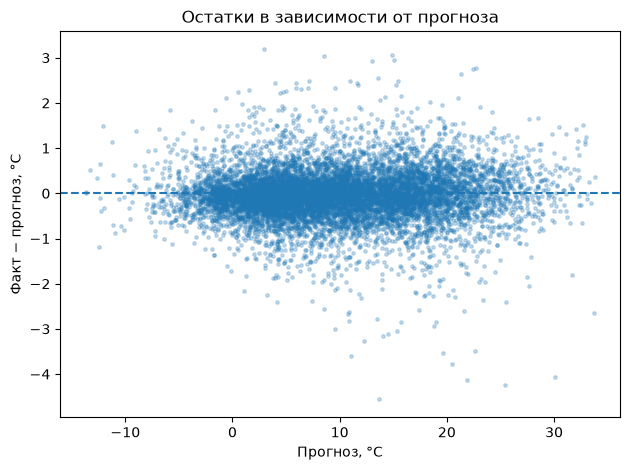

In [49]:
plt.figure(); plt.scatter(pred,err,s=6,alpha=.25); plt.axhline(0,ls="--"); chart("Остатки в зависимости от прогноза", "Прогноз, °C", "Факт − прогноз, °C")

По X — рассчитанная температура, по Y — подписанная ошибка. Желательно отсутствие выраженной зависимости остатков от уровня прогноза. Изгиб или расширение облака может означать систематическую проблему модели.

### Сравнение ошибок с базовой моделью

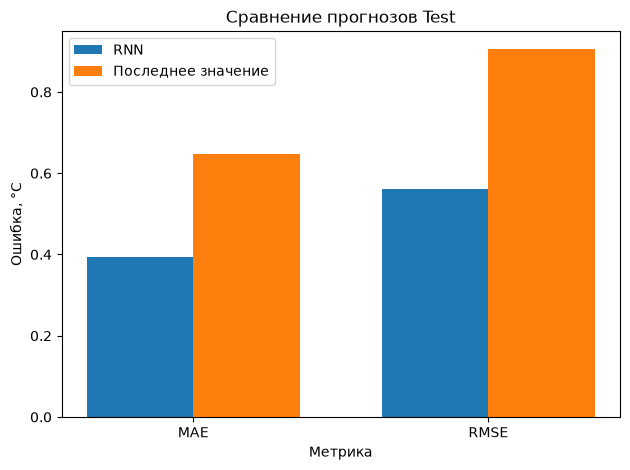

In [50]:
plt.figure(); names=["MAE","RMSE"]; pos=np.arange(2); plt.bar(pos-.18,[m["MAE (°C)"],m["RMSE (°C)"]],.36,label="RNN"); plt.bar(pos+.18,[m["Baseline MAE (°C)"],m["Baseline RMSE (°C)"]],.36,label="Последнее значение"); plt.xticks(pos,names); plt.legend(); chart("Сравнение прогнозов Test", "Метрика", "Ошибка, °C")

Сравниваются MAE и RMSE сети и базового прогноза на одних и тех же Test-окнах. Меньшая высота означает меньшую ошибку. Если RNN не выигрывает у базового метода, это ограничение необходимо отразить в выводе.

In [51]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"Для обучения сформировано {sizes['Train']} временных окон (они перекрываются внутри Train). MAE={m['MAE (°C)']:.3f} °C, RMSE={m['RMSE (°C)']:.3f} °C, R²={m['R2']:.3f}. Базовый MAE={m['Baseline MAE (°C)']:.3f} °C; " + ("по MAE сеть превосходит базовый прогноз." if m["MAE (°C)"]<m["Baseline MAE (°C)"] else "по MAE преимущество над базовым прогнозом не получено.")}
print(REPORT["conclusion"])

Для обучения сформировано 49066 временных окон (они перекрываются внутри Train). MAE=0.393 °C, RMSE=0.562 °C, R²=0.995. Базовый MAE=0.647 °C; по MAE сеть превосходит базовый прогноз.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.